# Light ROI extraction: simple thresholding (BTXRD)
Keeps only the bone region of every X-ray with simple thresholding **at its full size** (2440 x 2440), and only then makes it 512 x 512 (the same way as notebook 07).
The new images are saved as PNG in **`BTXRD_threshold_512.zip`**, in this folder. Inside the zip are the same `train`, `validation` and `test` folders, each with `normal` and `tumor`, as in `BTXRD_512.zip`. Every image stays in the same split as before.
The original data is only read, never changed.

Light ROI extraction keeps only the region of interest (ROI) of the X-ray and makes the rest black. Here the ROI is the bone region, as in the supervisor's guide ("isolate the bone region before classification"). It is a coarse mask, not an exact tumor outline.

Simple thresholding: every pixel brighter than one gray value (the threshold) belongs to the bone. The threshold is chosen for each X-ray with Otsu's method, which finds the gray value that best splits the X-ray into a dark and a bright group. It is measured on the X-ray only, not on the black square. One fixed threshold for all images would not work, because BTXRD X-rays differ a lot in brightness.

The mask is then cleaned up: small gaps are closed, holes are filled (so a dark lytic tumor inside a bone stays in), small specks are removed, and a safety margin of 50 pixels (about 10 pixels on the 512 x 512 image) is added around it.

Simple thresholding can cut away dim parts of a bone, and a tumor in them.

Note for the scores: where the mask makes part of the ring around a tumor black, CII changes too, so CII says less here than for the other methods.

## Settings

In [8]:
import io
import json
import zipfile
from collections import Counter
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

DATA = Path("../../../../data/BTXRD no duplicates")    # the original full-size images without duplicates (only read)
ANNOTATIONS = DATA / "Annotations"                     # tumor outlines (only read)
OLD_ZIP = Path("../../../../data/BTXRD_512.zip")       # the baseline zip (only read, to check the split)
NAME = "BTXRD_threshold_512"                           # the name of the new zip and of the folder inside it
NEW_ZIP = Path(NAME + ".zip")                          # the new zip is saved here, in this folder (Thresholding)
SPLITS = ["train", "validation", "test"]
MALIGNANT = {"osteosarcoma", "other mt"}               # all other tumor types are benign

SIZE = (512, 512)    # the same size as the baseline
CLOSE = 25           # mask clean-up: closes gaps up to 25 pixels wide
OPEN = 25            # mask clean-up: removes specks thinner than 25 pixels
MARGIN = 50          # mask clean-up: 50 pixels extra on every side (about 10 pixels on the 512 x 512 image)
BLACK = 15           # pixels at or below this are black background
RING = 10            # CII: width of the ring around the tumor, in pixels (on the 512 x 512 image)

## List the images
Every image in the `train`, `validation` and `test` folders, with its split, label (normal or tumor) and group (normal, benign or malignant).

In [9]:
def tumor_type(path):
    annotation = ANNOTATIONS / (path.stem + ".json")
    if not annotation.exists():
        return ""                                              # normal images have no annotation
    return json.loads(annotation.read_text())["shapes"][0]["label"]


records = []
for split in SPLITS:
    for path in sorted((DATA / split).glob("*/*.jp*g")):       # */ = normal or tumor, files end in .jpeg or .jpg
        kind = tumor_type(path)
        if kind == "":
            group = "normal"
        elif kind in MALIGNANT:
            group = "malignant"
        else:
            group = "benign"
        records.append({"image": path.stem, "split": split, "label": path.parent.name, "group": group, "path": path})

images = pd.DataFrame(records)
print(len(images), "images")
print(images.groupby(["split", "label"]).size())

3723 images
split       label 
test        normal     280
            tumor      279
train       normal    1306
            tumor     1300
validation  normal     280
            tumor      278
dtype: int64


## Check: the same split as `BTXRD_512.zip`
Every image must be in the same split (train, validation or test) and have the same label as in the baseline zip. If not, the notebook stops here.

In [10]:
with zipfile.ZipFile(OLD_ZIP) as old_zip:
    old_names = {name.removeprefix("BTXRD_512/").removesuffix(".png")   # for example train/normal/IMG001868
                 for name in old_zip.namelist() if name.endswith(".png")}
names = set(images["split"] + "/" + images["label"] + "/" + images["image"])

print("Images in BTXRD_512.zip:", len(old_names), "| images here:", len(names))
print("Same split and label for every image:", names == old_names)
assert names == old_names, "the split is not the same as in BTXRD_512.zip"

Images in BTXRD_512.zip: 3723 | images here: 3723
Same split and label for every image: True


## Functions
Load an image at full size, apply thresholding, make it 512 x 512, and find the X-ray inside the black square.

In [11]:
def load(path):
    image = Image.open(path).convert("L")                      # gray, pixels 0 (black) to 255 (white)
    return np.array(image)                                     # full size: 2440 x 2440


def disk(size):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))   # a round shape, size pixels wide


def clean(mask):
    mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_CLOSE, disk(CLOSE))   # close small gaps
    mask = ndimage.binary_fill_holes(mask).astype(np.uint8)   # fill holes, so a dark part inside a bone (like a lytic tumor) stays in
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, disk(OPEN))  # remove small specks
    return cv2.dilate(mask, disk(MARGIN)) == 1                 # a safety margin around the mask; True = keep


def threshold_roi(image):
    xray = image[image > BLACK]                                # the X-ray pixels, not the black square
    level, _ = cv2.threshold(xray.reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)   # Otsu: the best split into dark and bright
    mask = clean(image > level)                                # the bright part (the bone), cleaned up
    return np.where(mask, image, 0).astype(np.uint8)           # keep the X-ray inside the mask, black outside


def shrink(image):
    image = Image.fromarray(image).resize(SIZE, Image.LANCZOS)  # 512 x 512, the same way as notebook 07
    return np.array(image)


def xray_box(image):
    rows = np.where((image > BLACK).any(axis=1))[0]            # rows with something brighter than black
    cols = np.where((image > BLACK).any(axis=0))[0]            # the same for columns
    return rows[0], rows[-1] + 1, cols[0], cols[-1] + 1        # top, bottom, left, right

## Before and after: 2 normal, 2 benign, 2 malignant
Both at 512 x 512, the size the models see. Before = the baseline image (the same as in `BTXRD_512.zip`).

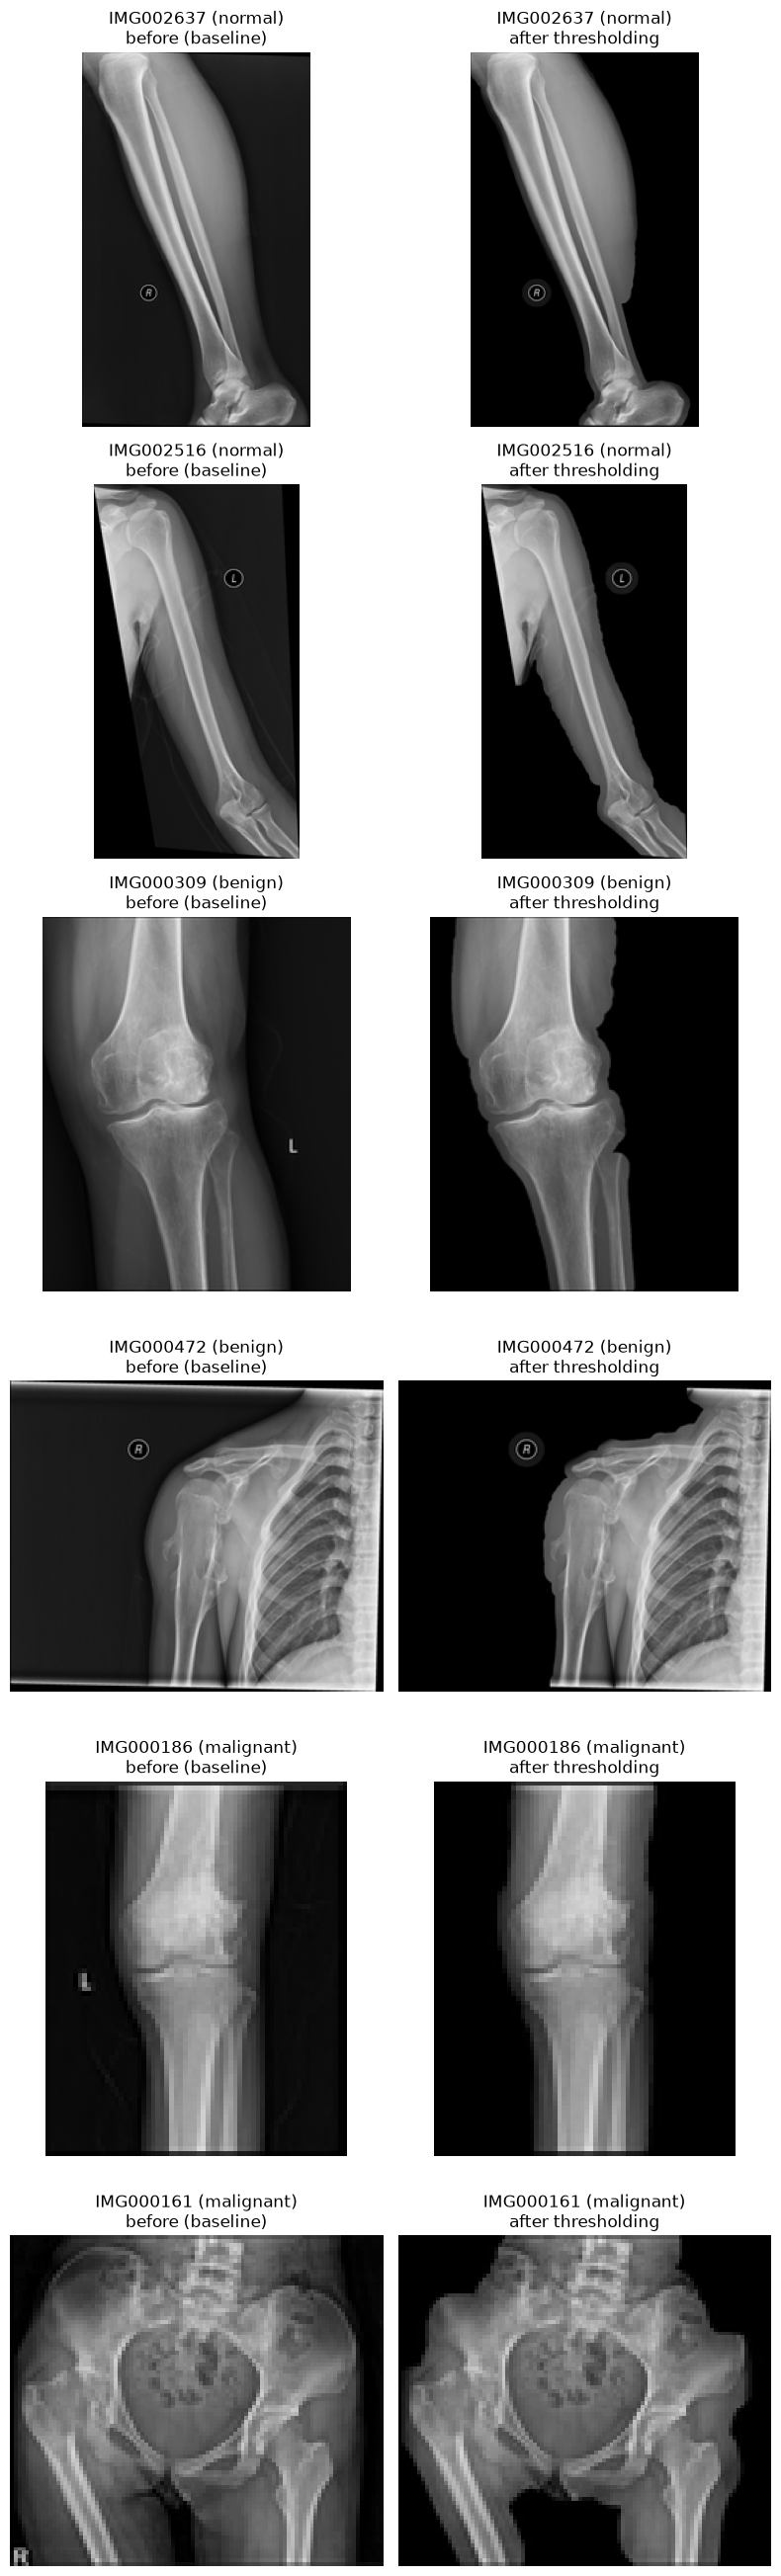

In [12]:
picks = pd.concat([images[images["group"] == group].sample(2, random_state=42)
                   for group in ["normal", "benign", "malignant"]])
titles = ["before (baseline)", "after thresholding"]

fig, axes = plt.subplots(len(picks), 2, figsize=(8, 4.4 * len(picks)))
for row, (_, pick) in zip(axes, picks.iterrows()):
    raw = load(pick["path"])
    before = shrink(raw)                                       # the baseline image
    after = shrink(threshold_roi(raw))                         # thresholding on the full image, then 512 x 512
    top, bottom, left, right = xray_box(before)                # cut away the black square, so the bone is big enough to see
    for ax, picture, title in zip(row, [before, after], titles):
        ax.imshow(picture[top:bottom, left:right], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{pick['image']} ({pick['group']})\n{title}")
        ax.axis("off")

plt.tight_layout()
plt.show()

## Measuring functions
Both images are compared at 512 x 512: the baseline image (before) and the new image (after).
- PSNR and SSIM: how much the image changed (higher = less change). Measured on the X-ray only, not the black square.
- CII: how much more the tumor stands out from the ring around it. Above 1 = it stands out more.

In [13]:
def tumor_mask(name):
    annotation = json.loads((ANNOTATIONS / (name + ".json")).read_text())
    scale = SIZE[0] / annotation["imageWidth"]                 # the outline was drawn on the 2440 x 2440 image
    mask = np.zeros((SIZE[1], SIZE[0]), dtype=np.uint8)
    for shape in annotation["shapes"]:
        if shape["shape_type"] == "polygon":                   # the outline (the rectangles are only boxes)
            points = np.round(np.array(shape["points"]) * scale).astype(np.int32)
            cv2.fillPoly(mask, [points], 1)
    return mask == 1                                           # True inside the tumor


def ring_around(tumor, before):
    kernel = np.ones((2 * RING + 1, 2 * RING + 1), dtype=np.uint8)
    bigger = cv2.dilate(tumor.astype(np.uint8), kernel) == 1   # the tumor made RING pixels bigger
    return bigger & ~tumor & (before > BLACK)                  # the ring: not the tumor, not the black background


def contrast(image, tumor, ring):
    t = image[tumor].mean()                                    # tumor brightness
    r = image[ring].mean()                                     # ring brightness
    return abs(t - r) / (t + r)                                # abs: a tumor can be darker or brighter than the bone


def cii(before, after, tumor, ring):
    if tumor.sum() == 0 or ring.sum() == 0:
        return np.nan                                          # cannot be measured
    contrast_before = contrast(before, tumor, ring)
    if contrast_before == 0:
        return np.nan                                          # cannot divide by 0
    return contrast(after, tumor, ring) / contrast_before


def psnr_ssim(before, after):
    top, bottom, left, right = xray_box(before)                # the X-ray only
    a, b = before[top:bottom, left:right], after[top:bottom, left:right]
    return peak_signal_noise_ratio(a, b, data_range=255), structural_similarity(a, b, data_range=255)

## Make every image, save it in the zip, and measure it
For every image: thresholding on the full image, then 512 x 512, then saved as PNG in the zip (`BTXRD_threshold_512/split/label/name.png`).
Then PSNR, SSIM and CII against the baseline image. CII is only for tumor images. This takes some minutes.

In [14]:
rows = []
with zipfile.ZipFile(NEW_ZIP, "w") as new_zip:                 # "w": makes a new zip (an old one with the same name is replaced)
    for n, (_, item) in enumerate(images.iterrows(), start=1):
        raw = load(item["path"])
        before = shrink(raw)                                   # the baseline image
        after = shrink(threshold_roi(raw))                     # thresholding on the full image, then 512 x 512

        png = io.BytesIO()                                     # make the PNG file in memory ...
        Image.fromarray(after).save(png, format="PNG")
        new_zip.writestr(f"{NAME}/{item['split']}/{item['label']}/{item['image']}.png", png.getvalue())   # ... and put it in the zip

        psnr, ssim = psnr_ssim(before, after)
        row = {"image": item["image"], "label": item["label"], "PSNR": psnr, "SSIM": ssim, "CII": np.nan}
        if item["label"] == "tumor":
            tumor = tumor_mask(item["image"])
            row["CII"] = cii(before, after, tumor, ring_around(tumor, before))
        rows.append(row)

        if n % 500 == 0:
            print(n, "of", len(images), "done")

scores = pd.DataFrame(rows)
print(len(images), "images saved in", NEW_ZIP)

/Users/refkarezkall/Desktop/bachelor/thesis work/bone-tumor-preprocessing/.venv/lib/python3.13/site-packages/skimage/metrics/simple_metrics.py:171: RuntimeWarning: divide by zero encountered in scalar divide
  return 10 * np.log10((data_range**2) / err)


500 of 3723 done
1000 of 3723 done


/var/folders/fb/hjp4syds4_b_t4g65_8szs_r0000gn/T/ipykernel_80864/2736606298.py:21: RuntimeWarning: invalid value encountered in scalar divide
  return abs(t - r) / (t + r)                                # abs: a tumor can be darker or brighter than the bone


1500 of 3723 done
2000 of 3723 done
2500 of 3723 done
3000 of 3723 done
3500 of 3723 done
3723 images saved in BTXRD_threshold_512.zip


## Check the new zip
Counts the images in each folder, checks that all are 512 x 512 gray images, and that every image is in the same split and label as in `BTXRD_512.zip`.

In [15]:
with zipfile.ZipFile(NEW_ZIP) as new_zip:
    files = [name for name in new_zip.namelist() if name.endswith(".png")]
    sizes, modes = Counter(), Counter()
    for name in files:
        image = Image.open(new_zip.open(name))
        sizes[image.size] += 1
        modes[image.mode] += 1                                 # L = gray

for folder, count in sorted(Counter(name.rsplit("/", 1)[0] for name in files).items()):
    print(folder, count)
print("Sizes:", dict(sizes), "| modes:", dict(modes))
new_names = {name.removeprefix(NAME + "/").removesuffix(".png") for name in files}
print("Same images, split and label as BTXRD_512.zip:", new_names == old_names)
print("Zip size:", round(NEW_ZIP.stat().st_size / 1e6), "MB")

BTXRD_threshold_512/test/normal 280
BTXRD_threshold_512/test/tumor 279
BTXRD_threshold_512/train/normal 1306
BTXRD_threshold_512/train/tumor 1300
BTXRD_threshold_512/validation/normal 280
BTXRD_threshold_512/validation/tumor 278
Sizes: {(512, 512): 3723} | modes: {'L': 3723}
Same images, split and label as BTXRD_512.zip: True
Zip size: 50 MB


## Results
The middle value (median) of each score: the image after thresholding compared with the baseline image. CII only counts the tumor images.

In [16]:
scores[["PSNR", "SSIM", "CII"]].median().round(3)

PSNR    20.912
SSIM     0.536
CII      1.123
dtype: float64